<a href="https://colab.research.google.com/github/pendulumswings/pendulumswings.github.io/blob/main/scripts/chapter7/jumping_pendulum_return_maps.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Jumping Pendulum Return Map comparison.

<>:106: SyntaxWarning: invalid escape sequence '\g'
<>:106: SyntaxWarning: invalid escape sequence '\g'
/tmp/ipykernel_1523/3930886537.py:106: SyntaxWarning: invalid escape sequence '\g'
  ax2.annotate('Light Friction ($\gamma=0.9$)\nExponential Trap Survives!', xy=(0.02, 0.05), xytext=(0.25, 0.4),


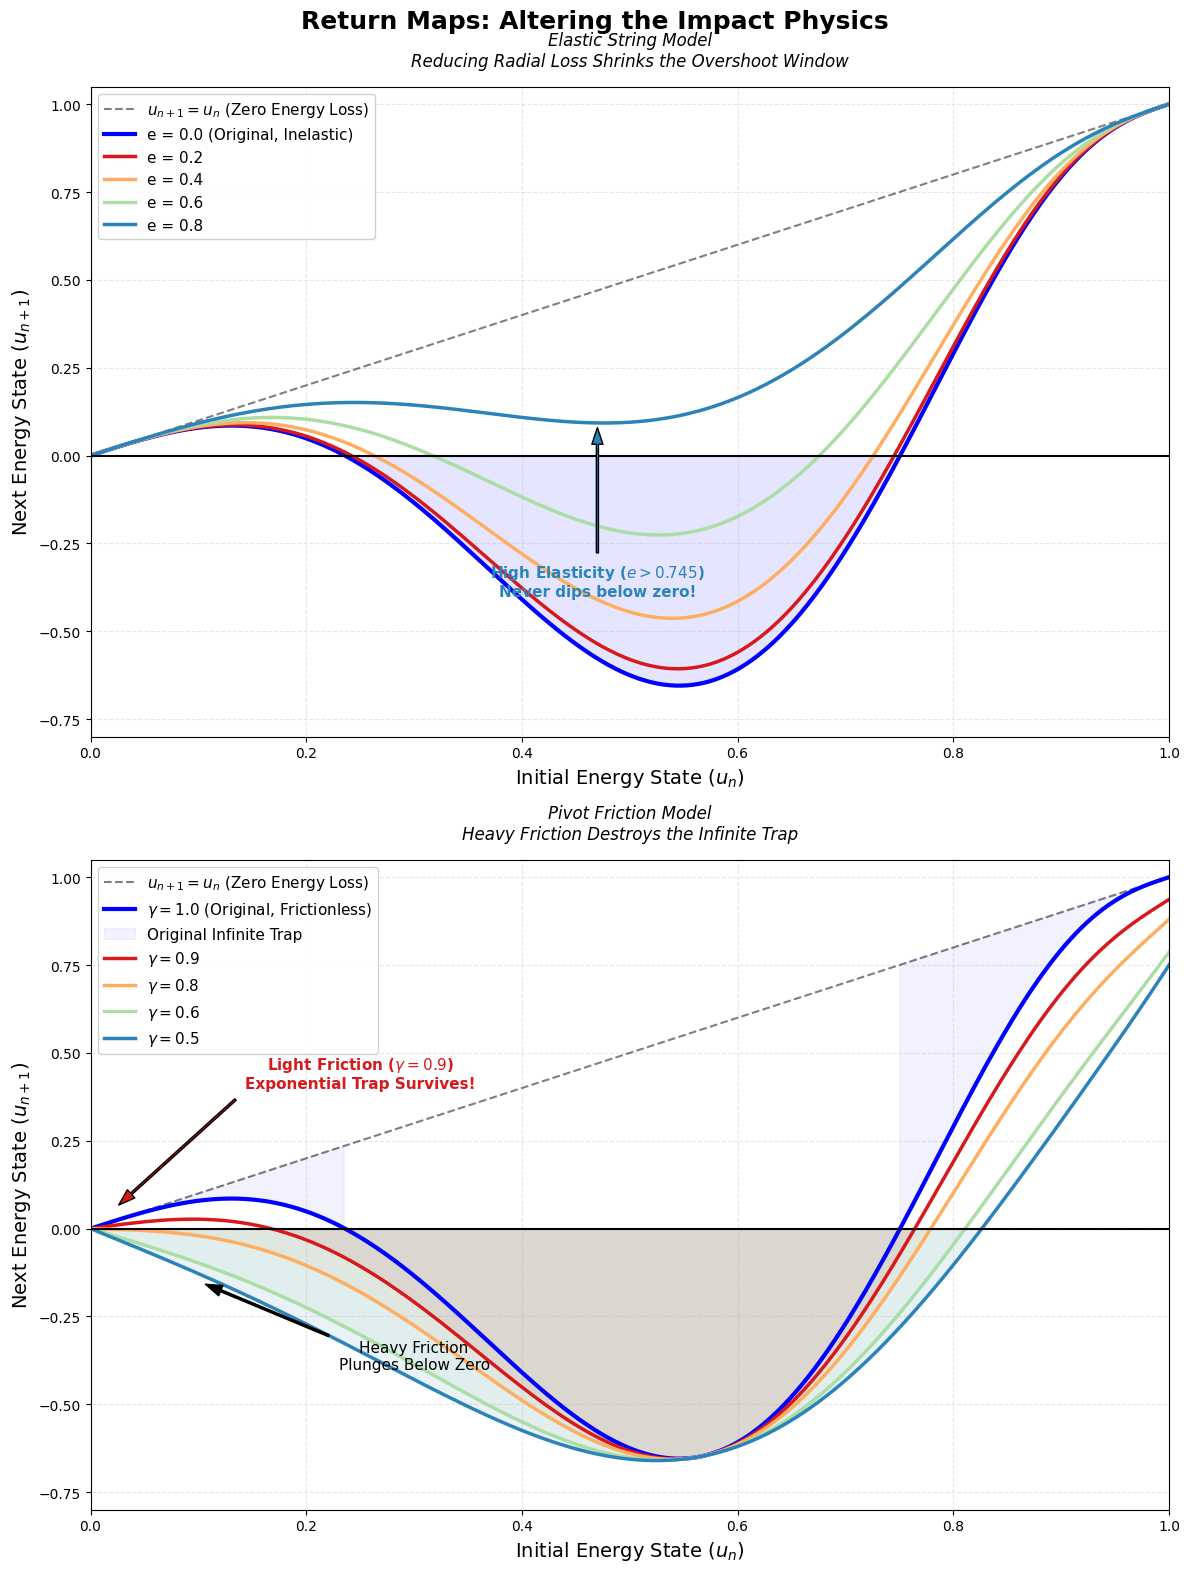

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def f(u, e=0.0):
    """
    The exact discrete return map for the elastic jumping pendulum.
    e = coefficient of restitution (0 = completely inelastic, 1 = perfectly elastic)
    """
    # The pure geometric loss function L(u)
    loss = (64/3) * (u**3) * (1 - u**2)**3

    # The new energy state factors in the retained normal velocity via (1 - e^2)
    return u - (1 - e**2) * loss

def f_friction(u, gamma=1.0):
    """
    The exact discrete return map for the pivot friction model.
    gamma = coefficient of tangential velocity retention (1 = no friction, 0 = complete brake)
    """
    # 1. The normal collision is ALWAYS 100% inelastic in this model
    loss_normal = (64/3) * (u**3) * (1 - u**2)**3

    # 2. Exact tangential kinetic energy translated into the state variable 'u' penalty
    loss_tangent = 3*u - (8/3)*(u**3) - loss_normal

    # Return current energy minus normal loss minus fraction of tangential loss
    return u - loss_normal - (1 - gamma**2) * loss_tangent

# Define the domain of energy states from pure oscillation (0) to top of circle (1)
u = np.linspace(0, 1, 1000)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 16))
plt.suptitle("Return Maps: Altering the Impact Physics", fontsize=18, fontweight='bold')

# ==========================================
# SUBPLOT 1: The Elastic String Model
# ==========================================
ax1.set_title("Elastic String Model\nReducing Radial Loss Shrinks the Overshoot Window", fontsize=12, style='italic', pad=15)

# Plot the identity line (y = x) where no energy is lost
ax1.plot(u, u, 'k--', alpha=0.5, label='$u_{n+1} = u_n$ (Zero Energy Loss)')

# Plot the original toy model (e=0) as the baseline
f_0 = f(u, 0.0)
ax1.plot(u, f_0, color='blue', linewidth=3, label='e = 0.0 (Original, Inelastic)')

# Highlight the original "Overshoot Window" where the curve dips below 0
ax1.fill_between(u, f_0, 0, where=(f_0 <= 0), color='blue', alpha=0.1)

# Define the restitution coefficients to test
e_values = [0.2, 0.4, 0.6, 0.8]
colors_e = ['#d7191c', '#fdae61', '#abdda4', '#2b83ba']

for e, color in zip(e_values, colors_e):
    f_e = f(u, e)
    ax1.plot(u, f_e, color=color, linewidth=2.5, label=f'e = {e}')

ax1.axhline(0, color='black', linewidth=1.5)
ax1.set_xlim(0, 1)
ax1.set_ylim(-0.8, 1.05)
ax1.set_xlabel('Initial Energy State ($u_n$)', fontsize=14)
ax1.set_ylabel('Next Energy State ($u_{n+1}$)', fontsize=14)

# Adding annotation to highlight the elasticity threshold
ax1.annotate('High Elasticity ($e > 0.745$)\nNever dips below zero!', xy=(0.47, 0.1), xytext=(0.47, -0.4),
             arrowprops=dict(facecolor='#2b83ba', shrink=0.05, width=1.5, headwidth=8),
             fontsize=11, ha='center', color='#2b83ba', fontweight='bold')

ax1.legend(loc='upper left', fontsize=11, framealpha=0.9)
ax1.grid(True, alpha=0.3, linestyle='--')

# ==========================================
# SUBPLOT 2: The Pivot Friction Model
# ==========================================
ax2.set_title("Pivot Friction Model\nHeavy Friction Destroys the Infinite Trap", fontsize=12, style='italic', pad=15)

# Plot the identity line (y = x)
ax2.plot(u, u, 'k--', alpha=0.5, label='$u_{n+1} = u_n$ (Zero Energy Loss)')

# Plot the original toy model (gamma=1.0) as the baseline
f_gamma_1 = f_friction(u, 1.0)
ax2.plot(u, f_gamma_1, color='blue', linewidth=3, label=r'$\gamma = 1.0$ (Original, Frictionless)')

# Highlight the original "Infinite Trap" interval
ax2.fill_between(u, f_gamma_1, u, where=(f_gamma_1 > 0), color='blue', alpha=0.05, label='Original Infinite Trap')

# Define the friction coefficients to test (gamma closer to 0 means MORE friction)
# We test 0.9 (above threshold) and 0.8, 0.6, 0.5 (below threshold)
gamma_values = [0.9, 0.8, 0.6, 0.5]
colors_g = ['#d7191c', '#fdae61', '#abdda4', '#2b83ba']

for gamma, color in zip(gamma_values, colors_g):
    f_g = f_friction(u, gamma)
    ax2.plot(u, f_g, color=color, linewidth=2.5, label=fr'$\gamma = {gamma}$')

    # Fill the massive new overshoot windows diving below the x-axis
    ax2.fill_between(u, f_g, 0, where=(f_g <= 0), color=color, alpha=0.1)

ax2.axhline(0, color='black', linewidth=1.5)
ax2.set_xlim(0, 1)
ax2.set_ylim(-0.8, 1.05)
ax2.set_xlabel('Initial Energy State ($u_n$)', fontsize=14)
ax2.set_ylabel('Next Energy State ($u_{n+1}$)', fontsize=14)

# Adding annotations to highlight the threshold physics
ax2.annotate('Light Friction ($\gamma=0.9$)\nExponential Trap Survives!', xy=(0.02, 0.05), xytext=(0.25, 0.4),
             arrowprops=dict(facecolor='#d7191c', shrink=0.05, width=1.5, headwidth=8),
             fontsize=11, ha='center', color='#d7191c', fontweight='bold')

ax2.annotate('Heavy Friction\nPlunges Below Zero', xy=(0.1, -0.15), xytext=(0.3, -0.4),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1.5, headwidth=8),
             fontsize=11, ha='center')

# Moved legend to the upper left!
ax2.legend(loc='upper left', fontsize=11, framealpha=0.9)
ax2.grid(True, alpha=0.3, linestyle='--')

plt.tight_layout()
plt.show()